# **Best Classification Model Selection**
Dataset: Diabetes (target `diabetes`: 0 = No, 1 = Yes)

Every model is tuned with cross-validation, all are compared, and the best one is selected and saved as `.pkl`.

| Type | Models |
|---|---|
| Linear | Logistic Regression |
| Naive Bayes | GaussianNB, CategoricalNB (binned) |
| Distance / Kernel | KNN, SVC |
| Tree | Decision Tree |
| Bagging | Bagging, Random Forest, Extra Trees |
| Boosting | AdaBoost, Gradient Boosting, HistGradientBoosting, XGBoost, LightGBM |
| Ensemble | Voting, Stacking (built from the best tuned models) |

(Softmax Regression is for 3 or more classes; here the target has 2 classes, where it is the same as Logistic Regression.)

**Imbalance:** only ~9% of patients are diabetic. Accuracy would be misleading (always saying "No" gives 91%), so we use a stratified split, stratified CV, `class_weight` / `scale_pos_weight` in the grids, **F1** to choose the model, and finally **threshold tuning** on the best model.

**Speed trick:** the parameter search runs on a **stratified sample of 20,000 rows** (SVC and KNN are slow on 77,000 rows). Every tuned model is then **trained again on the full training data** and tested on the test data.

### 1. Import

In [5]:
# In Google Colab xgboost and lightgbm are already installed. Locally run:  pip install xgboost lightgbm
import time, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import KBinsDiscretizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

### 2. Dataset, imbalance check and stratified split

In [6]:
df = pd.read_csv('../1. Data_Preprocessing/For_Classification/diabetes_after_preprocessing.csv')
x = df.drop('diabetes', axis=1)
y = df['diabetes']
print(df.shape, '| Diabetic %:', round(y.mean() * 100, 2))

# stratified train/test split (same 9% diabetic in both)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

# stratified sample of 20,000 rows, used only for the parameter search
x_tune, _, y_tune, _ = train_test_split(x_train, y_train, train_size=20000, random_state=0, stratify=y_train)
print('Train:', x_train.shape, '| Test:', x_test.shape, '| Tuning sample:', x_tune.shape)

# stratified 5-fold CV on the tuning sample (same folds for every model = fair comparison)
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(x_tune, y_tune))

cont_cols = ['age', 'bmi', 'hba1c_level', 'blood_glucose_level']
bin_cols = [c for c in x.columns if c not in cont_cols]

(96030, 12) | Diabetic %: 8.83
Train: (76824, 11) | Test: (19206, 11) | Tuning sample: (20000, 11)


### 3. Models and parameter search space
Each entry: `name: (model, parameters, type, n_iter)`
- `n_iter = None` -> **GridSearchCV** (every combination is tried)
- `n_iter = 8` -> **RandomizedSearchCV** (8 random combinations, for big spaces)

Models are tuned by **F1**. ROC-AUC is recorded too. Tree models do not need scaling; the other models use the already scaled data.

In [7]:
cw = [None, 'balanced']     # class_weight options (more weight to the rare diabetic class)

models = {
    # ---------------- Linear ----------------
    'LogisticRegression': (LogisticRegression(max_iter=1000),
        {'C': [0.01, 0.1, 1, 10], 'class_weight': cw}, 'Linear', None),

    # ---------------- Naive Bayes ----------------
    'GaussianNB': (GaussianNB(),
        {'var_smoothing': np.logspace(-9, 0, 10)}, 'Naive Bayes', None),
    'CategoricalNB (binned)': (
        Pipeline([('prep', ColumnTransformer([('cont', KBinsDiscretizer(encode='ordinal', strategy='uniform'), cont_cols),
                                              ('bin', 'passthrough', bin_cols)])),
                  ('model', CategoricalNB(min_categories=20))]),
        {'prep__cont__n_bins': [10, 20], 'model__alpha': [0.01, 0.1, 1]}, 'Naive Bayes', None),

    # ---------------- Distance / Kernel ----------------
    'KNN': (KNeighborsClassifier(algorithm='kd_tree'),
        {'n_neighbors': [5, 11, 21, 51], 'weights': ['uniform', 'distance']}, 'Distance/Kernel', None),
    'SVC': (SVC(kernel='rbf'),
        {'C': [1, 10], 'gamma': [0.003, 0.01, 0.03], 'class_weight': cw}, 'Distance/Kernel', None),

    # ---------------- Tree ----------------
    'DecisionTree': (DecisionTreeClassifier(random_state=42),
        {'max_depth': [3, 5, 7, 10, None], 'min_samples_leaf': [1, 10, 50], 'class_weight': cw}, 'Tree', None),

    # ---------------- Bagging family ----------------
    'Bagging': (BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42), random_state=42),
        {'n_estimators': [50, 100], 'max_samples': [0.6, 1.0], 'max_features': [0.6, 1.0],
         'estimator__max_depth': [None, 10]}, 'Bagging', 8),
    'RandomForest': (RandomForestClassifier(random_state=42),
        {'n_estimators': [100, 300], 'max_depth': [10, None], 'class_weight': cw}, 'Bagging', None),
    'ExtraTrees': (ExtraTreesClassifier(random_state=42),
        {'n_estimators': [100, 300], 'max_depth': [10, None], 'class_weight': cw}, 'Bagging', None),

    # ---------------- Boosting ----------------
    'AdaBoost': (AdaBoostClassifier(estimator=DecisionTreeClassifier(), random_state=42),
        {'n_estimators': [100, 200], 'learning_rate': [0.1, 0.5, 1.0], 'estimator__max_depth': [1, 2, 3]}, 'Boosting', 8),
    'GradientBoosting': (GradientBoostingClassifier(random_state=42),
        {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1], 'max_depth': [2, 3]}, 'Boosting', None),
    'HistGradientBoosting': (HistGradientBoostingClassifier(random_state=42),
        {'max_iter': [100, 300], 'learning_rate': [0.05, 0.1], 'max_depth': [None, 3, 5],
         'class_weight': cw}, 'Boosting', 8),
    'XGBoost': (XGBClassifier(random_state=42, n_jobs=1, verbosity=0),
        {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5],
         'scale_pos_weight': [1, 10]}, 'Boosting', 8),
    'LightGBM': (LGBMClassifier(random_state=42, n_jobs=1, verbose=-1, subsample_freq=1),
        {'n_estimators': [100, 300], 'learning_rate': [0.05, 0.1], 'num_leaves': [15, 31],
         'min_child_samples': [10, 20], 'scale_pos_weight': [1, 10]}, 'Boosting', 8),
}
print(len(models), 'models to tune')

14 models to tune


### 4. Helper: all metrics of a fitted model
`SVC` has no probabilities by default, so its ROC-AUC uses the `decision_function` score.

In [8]:
def get_scores(model, X, y_true):
    pred = model.predict(X)
    score = model.predict_proba(X)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X)
    return {'Accuracy': accuracy_score(y_true, pred), 'Precision': precision_score(y_true, pred),
            'Recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred),
            'ROC_AUC': roc_auc_score(y_true, score), 'PR_AUC': average_precision_score(y_true, score)}

results, tuned_models, model_type = [], {}, {}

### 5. Tune every model (best parameters)
For every model: search on the sample -> best parameters -> train again on the **full** training data -> test scores.

In [9]:
%%time
for name, (model, params, mtype, n_iter) in models.items():
    t0 = time.time()
    scoring = {'f1': 'f1', 'roc_auc': 'roc_auc'}
    if n_iter:
        search = RandomizedSearchCV(model, params, n_iter=n_iter, cv=cv, scoring=scoring, refit='f1',
                                    n_jobs=-1, random_state=42)
    else:
        search = GridSearchCV(model, params, cv=cv, scoring=scoring, refit='f1', n_jobs=-1)
    search.fit(x_tune, y_tune)

    best = clone(search.best_estimator_).fit(x_train, y_train)          # train again on ALL training rows
    tuned_models[name], model_type[name] = best, mtype

    sc = get_scores(best, x_test, y_test)
    results.append({'Model': name, 'Type': mtype, 'CV_F1': search.best_score_,
                    'CV_ROC_AUC': search.cv_results_['mean_test_roc_auc'][search.best_index_],
                    **{f'Test_{k}': v for k, v in sc.items()}, 'Best_Params': search.best_params_})
    print(f"{name:<24} CV F1 = {search.best_score_:.4f} | Test F1 = {sc['F1']:.4f} | Test AUC = {sc['ROC_AUC']:.4f} | {time.time()-t0:.0f}s")

LogisticRegression       CV F1 = 0.7332 | Test F1 = 0.7250 | Test AUC = 0.9593 | 41s
GaussianNB               CV F1 = 0.6948 | Test F1 = 0.6821 | Test AUC = 0.9422 | 2s
CategoricalNB (binned)   CV F1 = 0.7661 | Test F1 = 0.7630 | Test AUC = 0.9706 | 2s
KNN                      CV F1 = 0.7164 | Test F1 = 0.7305 | Test AUC = 0.9044 | 74s
SVC                      CV F1 = 0.7318 | Test F1 = 0.7356 | Test AUC = 0.9237 | 340s
DecisionTree             CV F1 = 0.8103 | Test F1 = 0.8048 | Test AUC = 0.9682 | 5s
Bagging                  CV F1 = 0.8108 | Test F1 = 0.8059 | Test AUC = 0.9750 | 40s
RandomForest             CV F1 = 0.8080 | Test F1 = 0.8037 | Test AUC = 0.9723 | 79s
ExtraTrees               CV F1 = 0.7815 | Test F1 = 0.7784 | Test AUC = 0.9478 | 36s
AdaBoost                 CV F1 = 0.8098 | Test F1 = 0.8053 | Test AUC = 0.9765 | 46s
GradientBoosting         CV F1 = 0.8134 | Test F1 = 0.8057 | Test AUC = 0.9774 | 89s
HistGradientBoosting     CV F1 = 0.8141 | Test F1 = 0.8071 | Test A

### 6. Ensemble Learning: Voting and Stacking
They are built from the best tuned models that can give probabilities.

- **Voting (soft):** averages the predicted probabilities of a team of models. We test every team (2 or more of the top 6 models) and keep the one with the best CV F1.
- **Stacking:** a meta model (Logistic Regression) learns how much to trust each of the top 4 models.

Both are scored with the same stratified CV on the 20,000-row sample, then trained on the full training data.

In [10]:
%%time
res_df = pd.DataFrame(results).sort_values('CV_F1', ascending=False)
proba_models = [n for n in res_df['Model'] if hasattr(tuned_models[n], 'predict_proba')]
top6, top4 = proba_models[:6], proba_models[:4]
print('Top 6 (Voting):', top6)
print('Top 4 (Stacking):', top4)

def oof_proba(model):
    # out-of-fold probabilities: every prediction is made by a model that did not see that row
    return cross_val_predict(clone(model), x_tune, y_tune, cv=cv, method='predict_proba', n_jobs=1)[:, 1]

# ---------- Voting: test every team ----------
oof = {n: oof_proba(tuned_models[n]) for n in top6}
best_team, best_f1 = None, -1
for size in range(2, len(top6) + 1):
    for team in itertools.combinations(top6, size):
        f1_team = f1_score(y_tune, (np.mean([oof[n] for n in team], axis=0) >= 0.5).astype(int))
        if f1_team > best_f1:
            best_team, best_f1 = list(team), f1_team
print('Best voting team:', best_team, '| CV F1:', round(best_f1, 4))

voting = VotingClassifier([(n, clone(tuned_models[n])) for n in best_team], voting='soft')
oof_voting = np.mean([oof[n] for n in best_team], axis=0)
voting.fit(x_train, y_train)

# ---------- Stacking ----------
stacking = StackingClassifier([(n, clone(tuned_models[n])) for n in top4],
                              final_estimator=LogisticRegression(max_iter=1000),
                              cv=3, stack_method='predict_proba', n_jobs=1)
oof_stacking = oof_proba(stacking)
stacking.fit(x_train, y_train)

for name, mdl, o, team in [('Voting', voting, oof_voting, best_team), ('Stacking', stacking, oof_stacking, top4)]:
    sc = get_scores(mdl, x_test, y_test)
    tuned_models[name], model_type[name] = mdl, 'Ensemble'
    results.append({'Model': name, 'Type': 'Ensemble', 'CV_F1': f1_score(y_tune, (o >= 0.5).astype(int)),
                    'CV_ROC_AUC': roc_auc_score(y_tune, o), **{f'Test_{k}': v for k, v in sc.items()},
                    'Best_Params': {'models': team}})
    print(f"{name:<9} CV F1 = {results[-1]['CV_F1']:.4f} | Test F1 = {sc['F1']:.4f} | Test AUC = {sc['ROC_AUC']:.4f}")

Top 6 (Voting): ['HistGradientBoosting', 'GradientBoosting', 'XGBoost', 'LightGBM', 'Bagging', 'DecisionTree']
Top 4 (Stacking): ['HistGradientBoosting', 'GradientBoosting', 'XGBoost', 'LightGBM']
Best voting team: ['HistGradientBoosting', 'GradientBoosting'] | CV F1: 0.8146
Voting    CV F1 = 0.8146 | Test F1 = 0.8058 | Test AUC = 0.9777
Stacking  CV F1 = 0.8137 | Test F1 = 0.8048 | Test AUC = 0.9775
CPU times: total: 4min 41s
Wall time: 3min 55s


### 7. All models compared (sorted by CV F1)

In [11]:
results_df = pd.DataFrame(results).sort_values('CV_F1', ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1
results_df.index.name = 'Rank'
results_df.drop(columns='Best_Params').round(4)

,Model,Type,CV_F1,CV_ROC_AUC,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC,Test_PR_AUC
Rank,,,,,,,,,,
1,Voting,Ensemble,0.8146,0.9789,0.9709,0.9806,0.6840,0.8058,0.9777,0.8822
2,HistGradientBoosting,Boosting,0.8141,0.9792,0.9711,0.9806,0.6857,0.8071,0.9778,0.8819
3,Stacking,Ensemble,0.8137,0.9781,0.9696,0.9311,0.7087,0.8048,0.9775,0.8821
4,GradientBoosting,Boosting,0.8134,0.9788,0.9709,0.9814,0.6834,0.8057,0.9774,0.8820
5,XGBoost,Boosting,0.8118,0.9785,0.9708,0.9922,0.6751,0.8035,0.9769,0.8807
6,LightGBM,Boosting,0.8109,0.9784,0.9709,0.9897,0.6781,0.8048,0.9775,0.8819
7,Bagging,Bagging,0.8108,0.9753,0.9710,0.9855,0.6816,0.8059,0.9750,0.8755
8,DecisionTree,Tree,0.8103,0.9672,0.9712,1.0000,0.6733,0.8048,0.9682,0.8395
9,AdaBoost,Boosting,0.8098,0.9769,0.9709,0.9838,0.6816,0.8053,0.9765,0.8770


### 8. Best model and its parameters
The best model is chosen by **CV F1** (the test set is not used for selection).

In [12]:
best = results_df.iloc[0]
best_name = best['Model']
best_model = tuned_models[best_name]

print('===== BEST CLASSIFICATION MODEL =====')
print('Model      :', best_name, f"({best['Type']})")
print(f"CV F1      : {best['CV_F1']:.4f}")
print(f"Test F1    : {best['Test_F1']:.4f}")
print(f"Test AUC   : {best['Test_ROC_AUC']:.4f}")
print(f"Precision  : {best['Test_Precision']:.4f} | Recall: {best['Test_Recall']:.4f}")
print('Parameters :', best['Best_Params'])

print('\n===== BEST MODEL OF EACH TYPE =====')
results_df.groupby('Type').head(1)[['Type', 'Model', 'CV_F1', 'Test_F1', 'Test_ROC_AUC']].round(4)

===== BEST CLASSIFICATION MODEL =====
Model      : Voting (Ensemble)
CV F1      : 0.8146
Test F1    : 0.8058
Test AUC   : 0.9777
Precision  : 0.9806 | Recall: 0.6840
Parameters : {'models': ['HistGradientBoosting', 'GradientBoosting']}

===== BEST MODEL OF EACH TYPE =====


,Type,Model,CV_F1,Test_F1,Test_ROC_AUC
Rank,,,,,
1,Ensemble,Voting,0.8146,0.8058,0.9777
2,Boosting,HistGradientBoosting,0.8141,0.8071,0.9778
7,Bagging,Bagging,0.8108,0.8059,0.9750
8,Tree,DecisionTree,0.8103,0.8048,0.9682
12,Naive Bayes,CategoricalNB (binned),0.7661,0.7630,0.9706
13,Linear,LogisticRegression,0.7332,0.7250,0.9593
14,Distance/Kernel,SVC,0.7318,0.7356,0.9237


### 9. Parameters of every model

In [13]:
for _, r in results_df.iterrows():
    print(f"{r['Model']:<24}", r['Best_Params'])

Voting                   {'models': ['HistGradientBoosting', 'GradientBoosting']}
HistGradientBoosting     {'max_iter': 300, 'max_depth': 3, 'learning_rate': 0.1, 'class_weight': None}
Stacking                 {'models': ['HistGradientBoosting', 'GradientBoosting', 'XGBoost', 'LightGBM']}
GradientBoosting         {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 300}
XGBoost                  {'scale_pos_weight': 1, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.1}
LightGBM                 {'scale_pos_weight': 1, 'num_leaves': 15, 'n_estimators': 100, 'min_child_samples': 20, 'learning_rate': 0.05}
Bagging                  {'n_estimators': 50, 'max_samples': 1.0, 'max_features': 1.0, 'estimator__max_depth': 10}
DecisionTree             {'class_weight': None, 'max_depth': 7, 'min_samples_leaf': 10}
AdaBoost                 {'n_estimators': 100, 'learning_rate': 1.0, 'estimator__max_depth': 3}
RandomForest             {'class_weight': None, 'max_depth': 10, 'n_estimators': 

### 10. Visualization
Left: CV F1. Middle: Test ROC-AUC. Right: precision vs recall of every model (top right is best). Green = the best model.

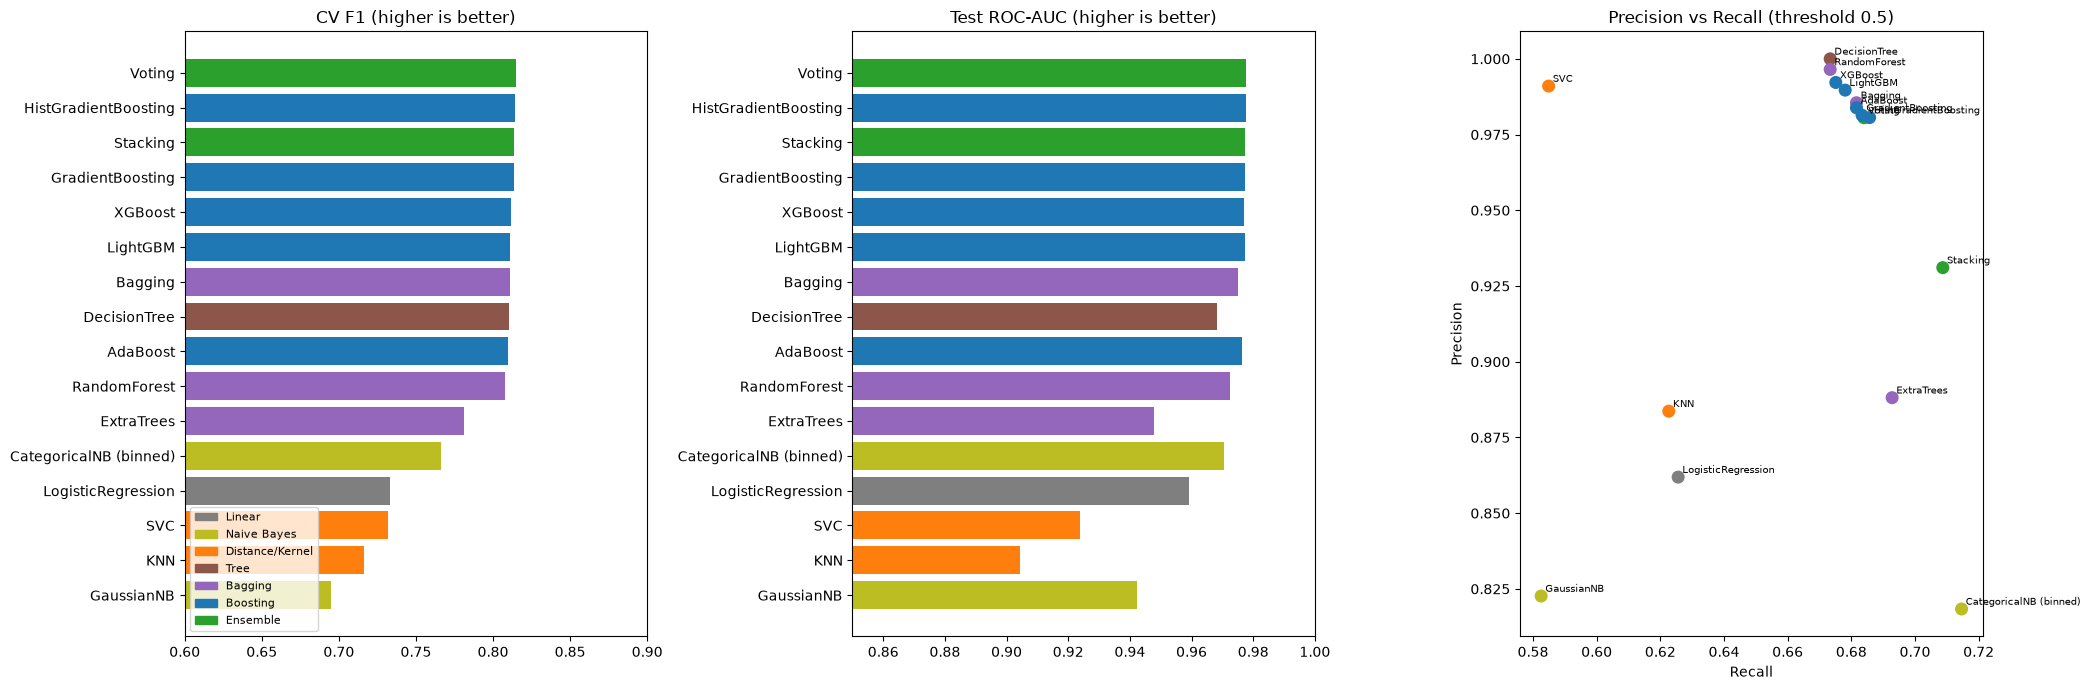

In [14]:
type_colors = {'Linear': 'tab:gray', 'Naive Bayes': 'tab:olive', 'Distance/Kernel': 'tab:orange', 'Tree': 'tab:brown',
              'Bagging': 'tab:purple', 'Boosting': 'tab:blue', 'Ensemble': 'tab:green'}
colors = results_df['Type'].map(type_colors)

fig, ax = plt.subplots(1, 3, figsize=(21, 7))
ax[0].barh(results_df['Model'], results_df['CV_F1'], color=colors)
ax[0].invert_yaxis(); ax[0].set_xlim(0.6, 0.9); ax[0].set_title('CV F1 (higher is better)')

ax[1].barh(results_df['Model'], results_df['Test_ROC_AUC'], color=colors)
ax[1].invert_yaxis(); ax[1].set_xlim(0.85, 1); ax[1].set_title('Test ROC-AUC (higher is better)')

ax[2].scatter(results_df['Test_Recall'], results_df['Test_Precision'], c=colors, s=70)
for _, r in results_df.iterrows():
    ax[2].annotate(r['Model'], (r['Test_Recall'], r['Test_Precision']), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision'); ax[2].set_title('Precision vs Recall (threshold 0.5)')

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in type_colors.values()]
ax[0].legend(handles, type_colors.keys(), loc='lower left', fontsize=8)
plt.tight_layout(); plt.show()

### 11. Handle imbalance: threshold tuning of the best model
At threshold 0.5 most models have high precision but miss many diabetic patients (low recall). We pick the probability cut-off with the best F1, using **out-of-fold CV predictions** (training data only, not the test set).

In [15]:
%%time
if best_name == 'Voting':
    oof_best = oof_voting
elif best_name == 'Stacking':
    oof_best = oof_stacking
elif hasattr(best_model, 'predict_proba'):
    oof_best = oof_proba(best_model)
else:
    oof_best = None
    print('Best model has no probabilities (SVC): threshold tuning skipped.')

p_test = best_model.predict_proba(x_test)[:, 1]
if oof_best is not None:
    prec, rec, thr = precision_recall_curve(y_tune, oof_best)
    f1_curve = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    best_thr = float(thr[np.argmax(f1_curve)])
else:
    best_thr = 0.5
print('Best threshold (max CV F1):', round(best_thr, 3))

rows = []
for t in sorted({0.5, round(best_thr, 3), 0.4, 0.3, 0.2, 0.1}, reverse=True):
    pred = (p_test >= t).astype(int)
    rows.append({'Threshold': t, 'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred), 'Missed diabetic': int(((pred == 0) & (y_test == 1)).sum()),
                 'False alarms': int(((pred == 1) & (y_test == 0)).sum())})
pd.DataFrame(rows).set_index('Threshold').round(3)

Best threshold (max CV F1): 0.372
CPU times: total: 1.42 s
Wall time: 2.88 s


,Precision,Recall,F1,Missed diabetic,False alarms
Threshold,,,,,
0.500,0.981,0.684,0.806,536,23
0.400,0.950,0.699,0.806,510,62
0.372,0.930,0.706,0.803,499,90
0.300,0.866,0.737,0.796,446,193
0.200,0.709,0.801,0.752,338,557
0.100,0.497,0.899,0.640,172,1544


### 12. Final model: best model + tuned threshold
Change `final_threshold` if you prefer more recall (catch more diabetic patients, more false alarms).

Voting with threshold 0.372
              precision    recall  f1-score   support

 No diabetes       0.97      0.99      0.98     17510
    Diabetes       0.93      0.71      0.80      1696

    accuracy                           0.97     19206
   macro avg       0.95      0.85      0.89     19206
weighted avg       0.97      0.97      0.97     19206



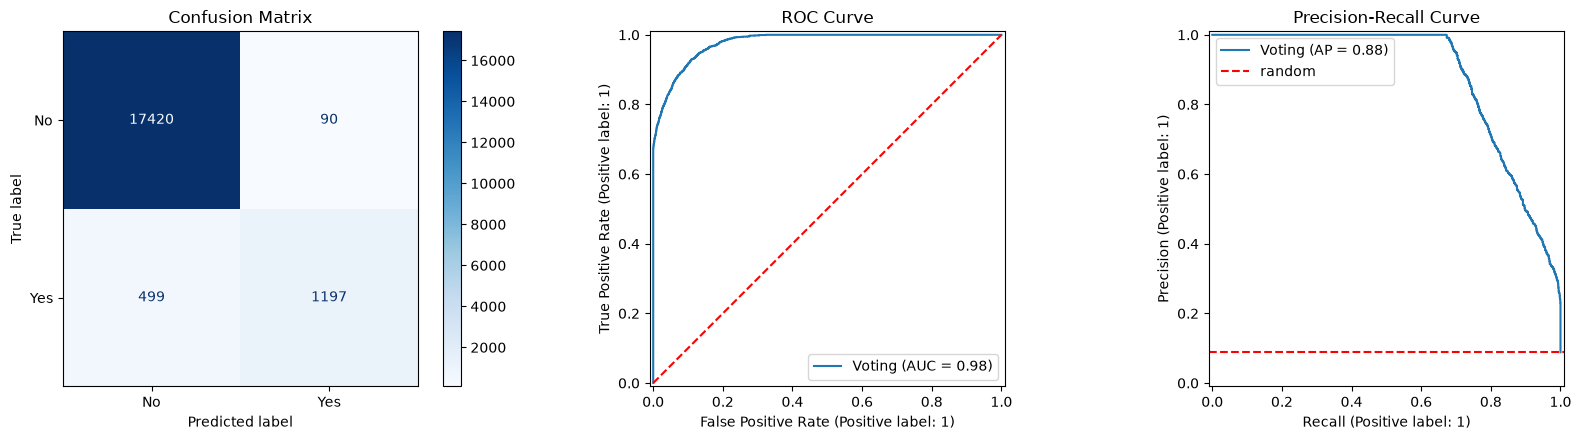

In [16]:
final_threshold = best_thr
final_pred = (p_test >= final_threshold).astype(int)

print(f'{best_name} with threshold {final_threshold:.3f}')
print(classification_report(y_test, final_pred, target_names=['No diabetes', 'Diabetes']))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=['No', 'Yes'], cmap='Blues', ax=ax[0])
ax[0].set_title('Confusion Matrix')
RocCurveDisplay.from_predictions(y_test, p_test, name=best_name, ax=ax[1]); ax[1].plot([0, 1], [0, 1], 'r--')
ax[1].set_title('ROC Curve')
PrecisionRecallDisplay.from_predictions(y_test, p_test, name=best_name, ax=ax[2])
ax[2].axhline(y_test.mean(), color='r', ls='--', label='random'); ax[2].legend(); ax[2].set_title('Precision-Recall Curve')
plt.tight_layout(); plt.show()

### 13. Save the best model (.pkl)
The best model (with its best parameters) is trained once more on **all data**. The threshold is saved with it.

In [17]:
%%time
final_model = clone(best_model).fit(x, y)

package = {'model': final_model, 'name': best_name, 'threshold': float(final_threshold),
           'params': best['Best_Params'], 'features': list(x.columns)}
joblib.dump(package, 'best_classification_model.pkl', compress=3)
results_df.to_csv('all_classification_results.csv')
print('Saved: best_classification_model.pkl, all_classification_results.csv')

Saved: best_classification_model.pkl, all_classification_results.csv
CPU times: total: 36.8 s
Wall time: 32.8 s


### 14. Load the model and predict

In [18]:
pkg = joblib.load('best_classification_model.pkl')
proba = pkg['model'].predict_proba(x_test.iloc[:5][pkg['features']])[:, 1]
print('Diabetes probability:', proba.round(3))
print('Prediction          :', (proba >= pkg['threshold']).astype(int))
print('Actual              :', y_test.iloc[:5].values)

Diabetes probability: [0.047 0.001 0.    0.15  0.001]
Prediction          : [0 0 0 0 0]
Actual              : [0 0 0 1 0]


(These 5 rows were also in the training data of the final model. This cell only checks that the saved file loads and predicts. The honest accuracy is in the test tables above.)

### 15. Download (Google Colab only)

In [19]:
try:
    from google.colab import files
    files.download('best_classification_model.pkl')
    files.download('all_classification_results.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
